In [ ]:
!pip install pydicom SimpleITK imageio tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 98.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 52.2 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import csv
import glob
import numpy as np
import pandas as pd
import SimpleITK as sitk
import imageio.v2 as imageio
from tqdm.notebook import tqdm

# ============================================================
# 🔧 USER CONFIGURATION — edit PROJECT_ROOT for your own setup
# ============================================================
PROJECT_ROOT = "/content/drive/MyDrive/lung_nodule_classification"

# --- 1. PATHS ---
# Download from https://lndb.grand-challenge.org/Data/
LNDB_ROOT = f"{PROJECT_ROOT}/raw_datasets/LNDb"
LNDB_CSV = os.path.join(LNDB_ROOT, "trainNodules.csv")

# Shared output (to merge with LIDC)
OUTPUT_ROOT = f"{PROJECT_ROOT}/extracted_patches/LNDb"

# Create subfolders
for cls in ["class_0", "class_1", "class_2"]:
    os.makedirs(os.path.join(OUTPUT_ROOT, cls), exist_ok=True)

# --- 2. CONFIGURATION ---
PATCH_SIZE = 64


In [ ]:
# --- 3. FUNCTIONS ---
def hu_to_uint8(patch, hu_window=(-1000, 400)):
    vmin, vmax = hu_window
    patch = np.clip(patch, vmin, vmax)
    patch = (patch - vmin) / (vmax - vmin + 1e-8)
    return (patch * 255.0).astype(np.uint8)

def extract_2_5d_patch(vol, center_xyz_voxel):
    """2.5D extraction (z-1, z, z+1)"""
    vx, vy, vz = center_xyz_voxel
    D, H, W = vol.shape
    pad = PATCH_SIZE // 2

    # Bounds checks
    if vz < 1 or vz >= D - 1: return None
    if vy < pad or vy >= H - pad: return None
    if vx < pad or vx >= W - pad: return None

    s0 = vol[vz-1, vy-pad:vy+pad, vx-pad:vx+pad]
    s1 = vol[vz,   vy-pad:vy+pad, vx-pad:vx+pad]
    s2 = vol[vz+1, vy-pad:vy+pad, vx-pad:vx+pad]
    return np.stack([s0, s1, s2], axis=-1)

# Class mapping based on the LNDb annotation scheme
def get_lndb_class(row):
    try:
        nodule_flag = int(row['Nodule'])
        text_score = int(row['Text'])

        # Class 0: Non-Nodule
        if nodule_flag == 0: return 0

        # Class 1 & 2: based on the 'Text' score
        if text_score == 3: return 1  # Benign
        if text_score == 5: return 2  # Malignant

        return None # Ignore 1, 2, 4 (ambiguous)
    except:
        return None


In [ ]:
# --- 4. EXECUTION ---
print(f"🚀 LNDb source: {LNDB_ROOT}")
print(f"📂 Destination: {OUTPUT_ROOT}")

if not os.path.exists(LNDB_CSV):
    print(f"❌ ERROR: CSV not found: {LNDB_CSV}")
else:
    df = pd.read_csv(LNDB_CSV)
    print(f"👉 {len(df)} annotations found.")

    # Metadata CSV specific to LNDb
    log_path = os.path.join(OUTPUT_ROOT, "metadata_lndb.csv")
    fieldnames = ["patch_path", "lndb_id", "class_label", "original_text", "finding_id"]

    if not os.path.exists(log_path):
        with open(log_path, "w", newline="") as f:
            csv.DictWriter(f, fieldnames=fieldnames).writeheader()

    stats = {0: 0, 1: 0, 2: 0}

    with open(log_path, "a", newline="") as csvfile:
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)

        # GroupBy Patient ID
        for lndb_id, group in tqdm(df.groupby('LNDbID'), desc="LNDb extraction"):

            # Image lookup (recursive, since the folder structure is complex)
            base_name = f"LNDb-{int(lndb_id):04d}"
            patterns = [f"**/{base_name}.mhd", f"**/{base_name}.nii.gz"]
            img_path = None

            for pat in patterns:
                matches = glob.glob(os.path.join(LNDB_ROOT, pat), recursive=True)
                if matches:
                    img_path = matches[0]
                    break

            if not img_path: continue

            try:
                # Read image & spatial metadata
                itk_img = sitk.ReadImage(img_path)
                vol = sitk.GetArrayFromImage(itk_img) # (Z, Y, X)
                origin = np.array(itk_img.GetOrigin())
                spacing = np.array(itk_img.GetSpacing())

                # Direction matrix (CRITICAL for LNDb)
                direction = np.array(itk_img.GetDirection()).reshape(3, 3)
                inv_direction = np.linalg.inv(direction)

                for idx, row in group.iterrows():
                    label = get_lndb_class(row)
                    if label is None: continue

                    # Precise voxel-coordinate computation (LNDb-specific math)
                    pt_mm = np.array([row['x'], row['y'], row['z']], dtype=float)
                    # World -> voxel transform accounting for patient orientation
                    voxel_idx = inv_direction.dot((pt_mm - origin) / spacing)

                    # Rounding (SimpleITK x,y,z -> Numpy z,y,x)
                    vx, vy, vz = int(round(voxel_idx[0])), int(round(voxel_idx[1])), int(round(voxel_idx[2]))

                    # Extraction
                    patch = extract_2_5d_patch(vol, (vx, vy, vz))

                    if patch is not None:
                        # Save
                        fname = f"LNDb-{int(lndb_id)}_find{row['FindingID']}_class{label}.png"
                        out_path = os.path.join(OUTPUT_ROOT, f"class_{label}", fname)

                        imageio.imwrite(out_path, hu_to_uint8(patch))

                        writer.writerow({
                            "patch_path": out_path, "lndb_id": lndb_id,
                            "class_label": label, "original_text": row['Text'],
                            "finding_id": row['FindingID']
                        })
                        stats[label] += 1

            except Exception:
                continue

    print("✅ LNDb extraction complete (separate folder)!")
    print(f"📊 Summary: Class 0={stats[0]}, Class 1={stats[1]}, Class 2={stats[2]}")


🚀 LNDb source: /content/drive/MyDrive/lung_nodule_classification/raw_datasets/LNDb
📂 Destination: /content/drive/MyDrive/lung_nodule_classification/extracted_patches/LNDb
👉 1527 annotations found.


LNDb extraction:   0%|          | 0/229 [00:00<?, ?it/s]

✅ LNDb extraction complete (separate folder)!
📊 Summary: Class 0=494, Class 1=70, Class 2=740


📊 Total LNDb images: 1304
Distribution:
class_label
0    494
1     70
2    740
Name: count, dtype: int64


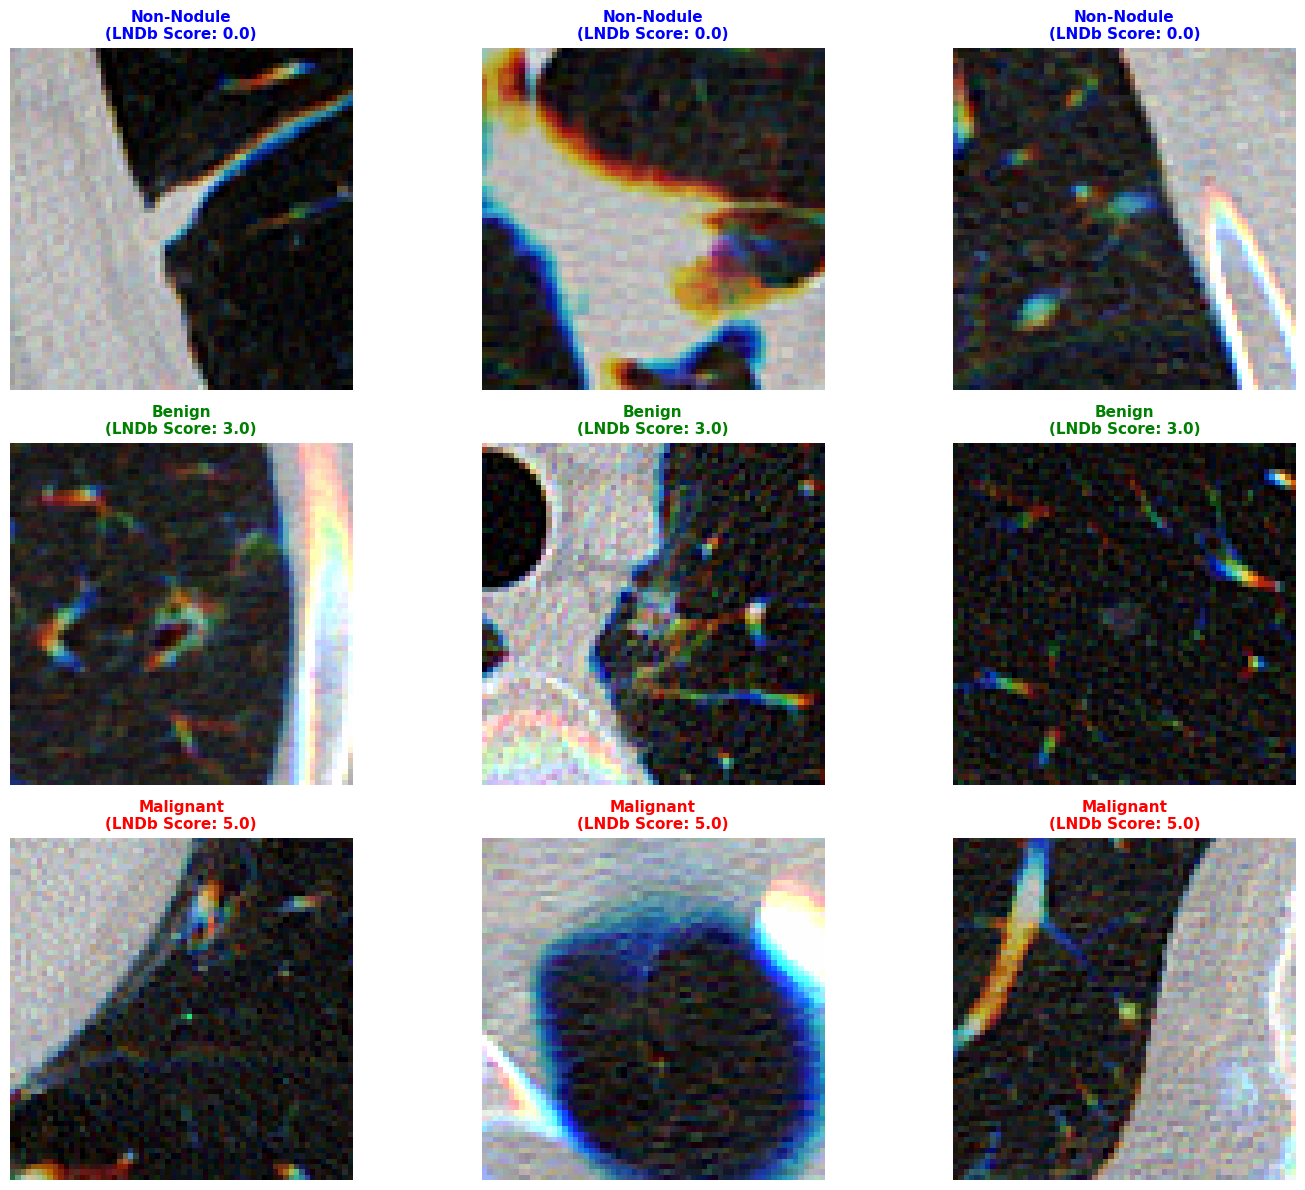

In [ ]:
# ==========================================
# LNDb DATA VISUALIZATION
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import os

# 1. Configuration (LNDb-specific path)
LNDB_OUTPUT_DIR = f"{PROJECT_ROOT}/extracted_patches/LNDb"  # NOTE: fixed, see Cell 1
csv_path = os.path.join(LNDB_OUTPUT_DIR, "metadata_lndb.csv")

if os.path.exists(csv_path):
    # Load metadata
    df = pd.read_csv(csv_path)

    if len(df) == 0:
        print("⚠️ The CSV file is empty.")
    else:
        print(f"📊 Total LNDb images: {len(df)}")
        print("Distribution:")
        print(df["class_label"].value_counts().sort_index())

        # 2. Display
        classes_present = sorted(df["class_label"].unique())
        samples_per_class = 3

        # Figure size adjusted to the number of classes
        plt.figure(figsize=(15, 4 * len(classes_present)))

        for i, cls in enumerate(classes_present):
            # Filter by class
            subset = df[df["class_label"] == cls]
            if subset.empty: continue

            # Take 3 random images
            n_samples = min(len(subset), samples_per_class)
            random_rows = subset.sample(n=n_samples)

            for j in range(n_samples):
                row = random_rows.iloc[j]
                img_path = row["patch_path"]

                # Position in the grid
                plt.subplot(len(classes_present), samples_per_class, i * samples_per_class + j + 1)

                if os.path.exists(img_path):
                    # Read and color-convert
                    img = cv2.imread(img_path)
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    plt.imshow(img)

                    # Titles & color
                    if cls == 0:
                        title = "Non-Nodule"
                        color = "blue"
                    elif cls == 1:
                        title = "Benign"
                        color = "green"
                    elif cls == 2:
                        title = "Malignant"
                        color = "red"
                    else:
                        title = f"Class {cls}"
                        color = "black"

                    # Show the original (Text) score for reference
                    orig_score = row.get('original_text', 'N/A')
                    plt.title(f"{title}\n(LNDb Score: {orig_score})",
                              color=color, fontweight='bold', fontsize=11)
                    plt.axis('off')
                else:
                    plt.text(0.5, 0.5, "Image not found", ha='center')
                    plt.axis('off')

        plt.tight_layout()
        plt.show()

else:
    print(f"❌ Metadata file not found here:\n{csv_path}")
    print("Check that the LNDb extraction has finished.")


In [ ]:
# =========================================================
# FINAL STEP: DATA AUGMENTATION (X4)
# Run ONLY once LIDC and LNDb extraction is finished
# =========================================================
import os
import cv2
import glob
from tqdm.notebook import tqdm

# Folders containing the extracted nodules
DIRS_TO_AUGMENT = [
    f"{PROJECT_ROOT}/extracted_patches/LNDb"  # NOTE: fixed, see Cell 1,
]

print("🚀 Starting augmentation (x4 rotation) to balance with LUNA16...")

total_gen = 0

for root_dir in DIRS_TO_AUGMENT:
    if not os.path.exists(root_dir):
        print(f"⚠️ Folder not found (fine if you haven't finished yet): {root_dir}")
        continue

    # Only touch the "nodule" classes (1 and 2)
    for class_id in [1, 2]:
        class_path = os.path.join(root_dir, f"class_{class_id}")
        if not os.path.exists(class_path): continue

        # Get all PNG images
        images = glob.glob(os.path.join(class_path, "*.png"))

        # Keep only ORIGINAL images (not the ones that already have _rot in the name)
        original_images = [img for img in images if "_rot" not in img]

        print(f"📂 {os.path.basename(root_dir)} | Class {class_id}: {len(original_images)} images to multiply.")

        for img_path in tqdm(original_images, desc=f"Augmentation {class_id}"):
            try:
                # Read
                img = cv2.imread(img_path)
                if img is None: continue

                # Generate the 3 rotations
                # 90° rotation
                cv2.imwrite(img_path.replace(".png", "_rot90.png"), cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE))
                # 180° rotation
                cv2.imwrite(img_path.replace(".png", "_rot180.png"), cv2.rotate(img, cv2.ROTATE_180))
                # 270° rotation
                cv2.imwrite(img_path.replace(".png", "_rot270.png"), cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE))

                total_gen += 3
            except Exception as e:
                continue

print(f"\n✅ DONE! {total_gen} new images created.")
print(f"🔥 ESTIMATED TOTAL NODULES: {len(original_images) * 4} (perfect to align with LUNA16!)")


🚀 Starting augmentation (x4 rotation) to balance with LUNA16...
📂 LNDb | Class 1: 65 images to multiply.


Augmentation 1:   0%|          | 0/65 [00:00<?, ?it/s]

📂 LNDb | Class 2: 522 images to multiply.


Augmentation 2:   0%|          | 0/522 [00:00<?, ?it/s]


✅ DONE! 1761 new images created.
🔥 ESTIMATED TOTAL NODULES: 2088 (perfect to align with LUNA16!)


In [ ]:
# =========================================================
# STEP 1: DATA AUGMENTATION (X4) - BALANCING
# =========================================================
import os
import cv2
import glob
from tqdm.notebook import tqdm

# 1. List of folders containing the nodules (Classes 1 and 2)
# Make sure these paths match your current folders on Drive
DIRS_TO_AUGMENT = [
    f"{PROJECT_ROOT}/extracted_patches/LNDb"  # NOTE: fixed, see Cell 1
]

print("🚀 Starting augmentation (x4 rotation) for the nodules...")
total_gen = 0

for root_dir in DIRS_TO_AUGMENT:
    if not os.path.exists(root_dir):
        print(f"⚠️ Folder not found (skipped): {root_dir}")
        continue

    # Only touch the "nodule" classes (1 and 2)
    for class_id in [1, 2]:
        class_path = os.path.join(root_dir, f"class_{class_id}")
        if not os.path.exists(class_path): continue

        # Get all PNG images
        images = glob.glob(os.path.join(class_path, "*.png"))

        # IMPORTANT FILTER: keep only ORIGINAL images
        # (avoid re-augmenting an already-rotated image if you rerun the script)
        original_images = [img for img in images if "_rot" not in img]

        print(f"📂 {os.path.basename(root_dir)} | Class {class_id}: {len(original_images)} images to multiply.")

        for img_path in tqdm(original_images, desc=f"Augmentation Cls {class_id}"):
            try:
                # Read
                img = cv2.imread(img_path)
                if img is None: continue

                # Generate the 3 rotations

                # 1. 90° rotation
                path_90 = img_path.replace(".png", "_rot90.png")
                if not os.path.exists(path_90):
                    cv2.imwrite(path_90, cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE))
                    total_gen += 1

                # 2. 180° rotation
                path_180 = img_path.replace(".png", "_rot180.png")
                if not os.path.exists(path_180):
                    cv2.imwrite(path_180, cv2.rotate(img, cv2.ROTATE_180))
                    total_gen += 1

                # 3. 270° rotation
                path_270 = img_path.replace(".png", "_rot270.png")
                if not os.path.exists(path_270):
                    cv2.imwrite(path_270, cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE))
                    total_gen += 1

            except Exception as e:
                continue

print(f"\n✅ DONE! {total_gen} new images created.")
print(f"📈 Your 'Class 1' and 'Class 2' folders are now 4x bigger.")


🚀 Starting augmentation (x4 rotation) for the nodules...
📂 LNDb | Class 1: 65 images to multiply.


Augmentation Cls 1:   0%|          | 0/65 [00:00<?, ?it/s]

📂 LNDb | Class 2: 522 images to multiply.


Augmentation Cls 2:   0%|          | 0/522 [00:00<?, ?it/s]


✅ DONE! 0 new images created.
📈 Your 'Class 1' and 'Class 2' folders are now 4x bigger.


In [ ]:
# =========================================================
# SUPER-AUGMENTATION (Flip + Brightness)
# Goal: reach ~16,000 images per class
# =========================================================
import os
import cv2
import glob
import numpy as np
from tqdm.notebook import tqdm

# Nodule folders
DIRS = [
    f"{PROJECT_ROOT}/extracted_patches/LNDb"  # NOTE: fixed, see Cell 1
]

def adjust_gamma(image, gamma=1.2):
    # Non-linear brightness change
    invGamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** invGamma) * 255
                      for i in np.arange(0, 256)]).astype("uint8")
    return cv2.LUT(image, table)

print("🚀 Starting Super-Augmentation...")
total_new = 0

for root_dir in DIRS:
    if not os.path.exists(root_dir): continue

    # Target only the nodule classes (1 and 2)
    for class_id in [1, 2]:
        class_path = os.path.join(root_dir, f"class_{class_id}")
        if not os.path.exists(class_path): continue

        # Take ALL current images (originals + rotations)
        # But exclude the ones we're about to create (_flip, _bright) to avoid infinite loops
        all_current_images = glob.glob(os.path.join(class_path, "*.png"))
        targets = [f for f in all_current_images if "_flip" not in f and "_bright" not in f]

        print(f"📂 {os.path.basename(root_dir)} | Class {class_id}: {len(targets)} base images to multiply.")

        for img_path in tqdm(targets, desc=f"Boosting Class {class_id}"):
            try:
                img = cv2.imread(img_path)
                if img is None: continue

                # --- 1. MIRROR GENERATION (FLIP) ---
                # Creates a horizontal flip
                path_flip = img_path.replace(".png", "_flip.png")
                if not os.path.exists(path_flip):
                    flipped = cv2.flip(img, 1)
                    cv2.imwrite(path_flip, flipped)
                    total_new += 1
                else:
                    flipped = cv2.imread(path_flip) # Load it for the next step

                # --- 2. BRIGHTNESS GENERATION (ON THE ORIGINAL) ---
                path_bright = img_path.replace(".png", "_bright.png")
                if not os.path.exists(path_bright):
                    bright = adjust_gamma(img, gamma=1.2)
                    cv2.imwrite(path_bright, bright)
                    total_new += 1

                # --- 3. BRIGHTNESS GENERATION (ON THE FLIP) ---
                # To maximize the count
                path_flip_bright = img_path.replace(".png", "_flip_bright.png")
                if not os.path.exists(path_flip_bright) and flipped is not None:
                    bright_flip = adjust_gamma(flipped, gamma=1.2)
                    cv2.imwrite(path_flip_bright, bright_flip)
                    total_new += 1

            except Exception:
                continue

print(f"\n✅ DONE! {total_new} new images generated.")


🚀 Starting Super-Augmentation...
📂 LNDb | Class 1: 260 base images to multiply.


Boosting Class 1:   0%|          | 0/260 [00:00<?, ?it/s]

📂 LNDb | Class 2: 2088 base images to multiply.


Boosting Class 2:   0%|          | 0/2088 [00:00<?, ?it/s]


✅ DONE! 7044 new images generated.
